# Diurnal cycle of isoprene emission (MEGAN exact-split branch runs)

**What:** the diurnal cycle of the isoprene flux the atmosphere receives (`SFISOP`, MEGAN, kg m⁻² s⁻¹), from the 30-min CAM tape of the MEGAN exact-split branch runs, in **local solar time**.

**Runs (aliases):** `CTRL_PD`, `LCC_PD`, `CTRL_FUT`, `LCC_FUT`, the `_meganpatch_` branch chains (`-from2000` hybrid, `-from2005`, `-from2010`). Years 2001–02, 2005–06, 2010–11 (2000 = hybrid year, not used). FUT batch 2 (2002, 2006, 2011) is used only once reduced; the years actually read are printed below.

**Input:** `data/processed-data/isoprene-diurnal/diurnal_<ALIAS>_<YEAR>.nc` from `reduce_isoprene_diurnal.py` (this folder): for each month, the mean over its days of each 30-min UTC step. The raw `cam.h1` files on `/cluster/work` are purged ~Dec 2026, the reduced files stay on NIRD.

**Choices**
- `SFISOP` on tape h1 is **instantaneous** (`avgflag_pertape = 'A','I'`): a value stamped *t* is the flux of the step ending at *t*, assigned to the step centre *t* − 15 min.
- **Local solar time** = UTC + lon/15 h, rounded to the 30-min step (error ≤ 10 min).
- Regional values are **totals** (flux × grid-cell area; `SFISOP` is per m² of grid cell), in Mg h⁻¹.
- Regions: **LCC-modified cells** (`diagnostics/lcc-modified-cells/modified_cells.nc`, any natural-PFT change) and **all cells ≥ 45°N**.
- Spread: shading = min–max across years; LCC − CTRL = paired yearly differences, mean ± 95 % t-interval (n = years).

In [1]:
from pathlib import Path
import glob, re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
IN_DIR = ROOT / "data/processed-data/isoprene-diurnal"
MASK = ROOT / "diagnostics/lcc-modified-cells/modified_cells.nc"
OUT = ROOT / "diagnostics/2_isoprene-diurnal-cycle/isoprene_diurnal_cycle_outputs"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)

# project palette (src/boreal_forest_expansion/plotting/palette.py), in order; gold = total
TEAL, NAVY, PLUM, RED, ORANGE, GOLD, LGREY = "#5D9A92", "#2C3990", "#9A4A84", "#BC423E", "#DE7A3A", "#EBC45C", "#CCCCCC"
COL = {"CTRL": NAVY, "LCC": RED}
LS = {"PD": "-", "FUT": "--"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
SEASONS = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}
DAYS = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

## 1. Load the reduced files (years present for both CTRL and LCC of a period)

In [2]:
files = {}
for f in sorted(IN_DIR.glob("diurnal_*_*.nc")):
    m = re.match(r"diurnal_(CTRL|LCC)_(PD|FUT)_(\d{4})\.nc", f.name)
    files[(m[1], m[2], int(m[3]))] = f

YEARS = {}
for per in ("PD", "FUT"):
    yc = {y for (v, p, y) in files if v == "CTRL" and p == per}
    yl = {y for (v, p, y) in files if v == "LCC" and p == per}
    YEARS[per] = sorted(yc & yl)
    print(f"{per}: years used {YEARS[per]}  (CTRL only: {sorted(yc - yl)}, LCC only: {sorted(yl - yc)})")

def load(veg, per):
    das = []
    for y in YEARS[per]:
        ds = xr.open_dataset(files[(veg, per, y)])
        assert ds.n_days.values.min() == ds.n_days.values.max() or True
        das.append(ds.SFISOP.load().expand_dims(year=[y]))
        print(f"  {veg}_{per} {y}: {ds.attrs['case']}")
    return xr.concat(das, "year")

DATA = {(v, p): load(v, p) for p in ("PD", "FUT") if YEARS[p] for v in ("CTRL", "LCC")}
ref = next(iter(DATA.values()))
lat, lon = ref.lat.values, ref.lon.values

PD: years used [2001, 2002, 2005, 2006, 2010, 2011]  (CTRL only: [], LCC only: [])
FUT: years used [2001, 2005, 2010]  (CTRL only: [], LCC only: [])
  CTRL_PD 2001: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000
  CTRL_PD 2002: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000
  CTRL_PD 2005: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005
  CTRL_PD 2006: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005
  CTRL_PD 2010: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2010
  CTRL_PD 2011: NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2010
  LCC_PD 2001: NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000
  LCC_PD 2002: NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000
  LCC_PD 2005: NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2005
  LCC_PD 2006: NF2000norbc_tropstratchem_nudg_lcc_meganp

## 2. UTC → local solar time, cell areas, regions

In [3]:
# shift each longitude column by round(lon/7.5) half-hour steps: value at LST step k = UTC step (k - shift) mod 48
lon180 = np.where(lon > 180, lon - 360, lon)
shift = np.rint(lon180 / 7.5).astype(int)
idx = (np.arange(48)[:, None] - shift[None, :]) % 48          # (step, lon)

def to_lst(da):
    a = da.values                                              # (..., step, lat, lon)
    ix = np.broadcast_to(idx[:, None, :], a.shape[-3:])
    out = np.take_along_axis(a, np.broadcast_to(ix, a.shape), axis=-3)
    return da.copy(data=out).rename(step="lst")

LST = {k: to_lst(v) for k, v in DATA.items()}
HOURS = ref.step.values                                       # step centres 0.25 … 23.75 h

# grid-cell area from the cell edges (sphere, R = 6371.22 km as in CLM)
R = 6.37122e6
lat_e = np.concatenate([[-90], 0.5 * (lat[1:] + lat[:-1]), [90]])
dlon = np.deg2rad(lon[1] - lon[0])
area = (R**2 * dlon * np.diff(np.sin(np.deg2rad(lat_e))))[:, None] * np.ones(lon.size)   # m2
area = xr.DataArray(area, coords={"lat": lat, "lon": lon}, dims=("lat", "lon"))
print(f"total area {area.sum().item()/5.1e14:.4f} × 5.1e14 m²")

mod = xr.open_dataset(MASK).modified
assert np.allclose(mod.lat, lat) and np.allclose(mod.lon, lon)
mod = xr.DataArray(mod.values.astype(bool), coords=area.coords)
REGIONS = {
    "LCC-modified cells": mod,
    "≥ 45°N": xr.DataArray(np.broadcast_to(lat[:, None] >= 45, area.shape), coords=area.coords),
}
for r, m in REGIONS.items():
    print(f"{r}: {int(m.sum())} cells, {float(area.where(m).sum())/1e12:.2f} Mkm²")

KG_S_TO_MG_H = 3600 / 1e3     # kg s-1 → Mg h-1

def regional_total(da, mask):
    # Mg h-1, dims (year, month, lst); numpy contraction over (lat, lon), much faster than where().sum()
    w = (area * mask).values
    vals = np.tensordot(da.values, w, axes=([-2, -1], [0, 1])) * KG_S_TO_MG_H
    return xr.DataArray(vals, coords={d: da[d] for d in da.dims[:-2]}, dims=da.dims[:-2])

REG = {(r, v, p): regional_total(LST[(v, p)], m) for r, m in REGIONS.items() for (v, p) in LST}

def season_mean(x, months):
    w = xr.DataArray(DAYS[np.array(months) - 1], coords={"month": months})
    return x.sel(month=months).weighted(w).mean("month")

total area 1.0002 × 5.1e14 m²
LCC-modified cells: 1161 cells, 29.13 Mkm²
≥ 45°N: 3456 cells, 73.22 Mkm²


### Check: daily totals vs a direct sum

The regional total integrated over the day (sum of 48 half-hour rates × 0.5 h) and over the year must equal the yearly emission. A check against the MEGAN LMDI reduced totals is not done here; this cell only reports the annual totals (Tg yr⁻¹) for reference.

In [4]:
rows = []
for (r, v, p), x in REG.items():
    daily = x.sum("lst") * 0.5                           # Mg per mean day of that month
    annual = (daily * xr.DataArray(DAYS, coords={"month": np.arange(1, 13)})).sum("month") / 1e6   # Tg yr-1
    for y in x.year.values:
        rows.append(dict(region=r, alias=f"{v}_{p}", year=int(y), isoprene_Tg_per_yr=float(annual.sel(year=y))))
tot = pd.DataFrame(rows)
tab = tot.pivot_table(index=["region", "alias"], columns="year", values="isoprene_Tg_per_yr").round(3)
tab.to_csv(OUT / "tables/annual_isoprene_totals_Tg.csv")
tab

year                           2001   2002    2005    2006    2010   2011
region             alias                                                 
LCC-modified cells CTRL_FUT  12.511    NaN  13.116     NaN  12.477    NaN
                   CTRL_PD    4.227  3.663   4.332   4.418   4.030  3.747
                   LCC_FUT   13.116    NaN  13.567     NaN  12.780    NaN
                   LCC_PD     4.582  3.865   4.584   4.693   4.154  3.930
≥ 45°N             CTRL_FUT  23.149    NaN  24.322     NaN  23.848    NaN
                   CTRL_PD    9.460  8.261   9.860  10.246   9.738  8.687
                   LCC_FUT   23.813    NaN  24.807     NaN  24.068    NaN
                   LCC_PD     9.885  8.547  10.160  10.553   9.841  8.873

## 3. Diurnal cycle by season

Regional total isoprene emission rate (Mg h⁻¹) against local solar time. Lines = mean over years, shading = min–max across years. CTRL navy, LCC red; PD solid, FUT dashed.

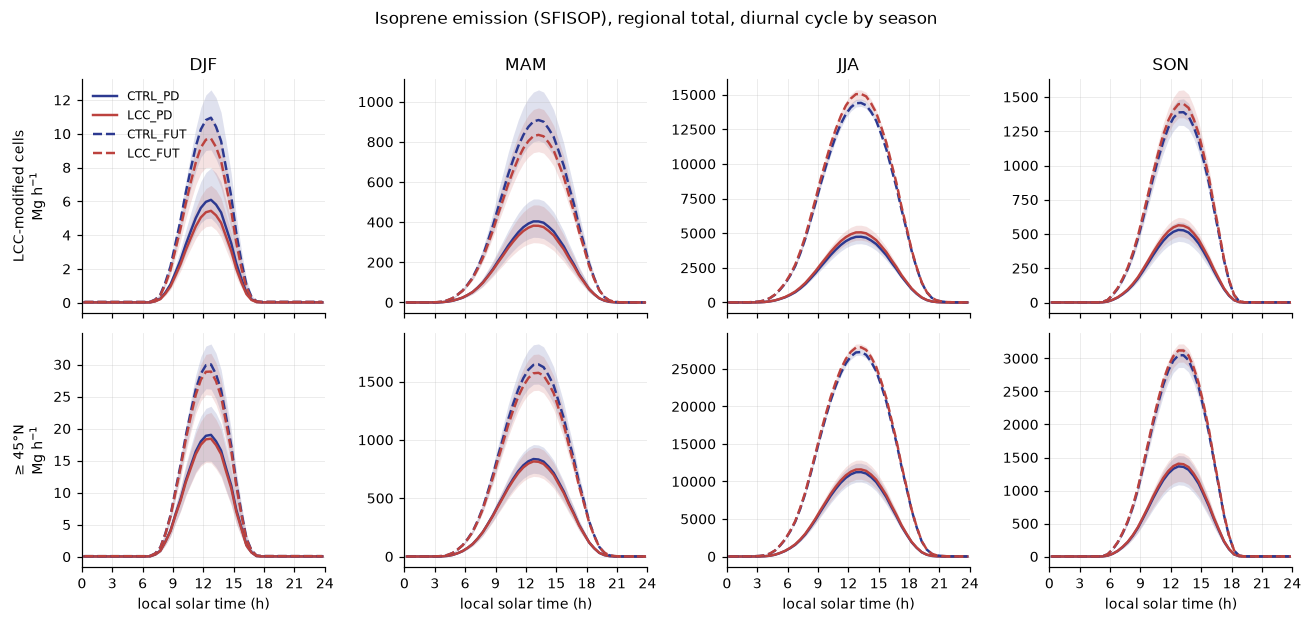

In [5]:
fig, axes = plt.subplots(len(REGIONS), 4, figsize=(12, 5.6), sharex=True)
for i, r in enumerate(REGIONS):
    for j, (s, mo) in enumerate(SEASONS.items()):
        ax = axes[i, j]
        for p in ("PD", "FUT"):
            for v in ("CTRL", "LCC"):
                if (r, v, p) not in REG:
                    continue
                x = season_mean(REG[(r, v, p)], mo)
                ax.plot(HOURS, x.mean("year"), color=COL[v], ls=LS[p], lw=1.6, label=f"{v}_{p}")
                ax.fill_between(HOURS, x.min("year"), x.max("year"), color=COL[v], alpha=0.15, lw=0)
        ax.set_xticks(range(0, 25, 3)); ax.set_xlim(0, 24)
        ax.grid(alpha=0.3, lw=0.5)
        if i == 0: ax.set_title(s)
        if j == 0: ax.set_ylabel(f"{r}\nMg h$^{{-1}}$")
        if i == len(REGIONS) - 1: ax.set_xlabel("local solar time (h)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Isoprene emission (SFISOP), regional total, diurnal cycle by season", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_diurnal_by_season.png", dpi=200, bbox_inches="tight")

## 4. LCC − CTRL: absolute and relative

Paired yearly differences (same nudged weather in CTRL and LCC), mean ± 95 % t-interval, growing season (MJJAS) and JJA. Relative change = Δ / CTRL of the same hour (shown only where CTRL exceeds 5 % of its daily peak).

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctio

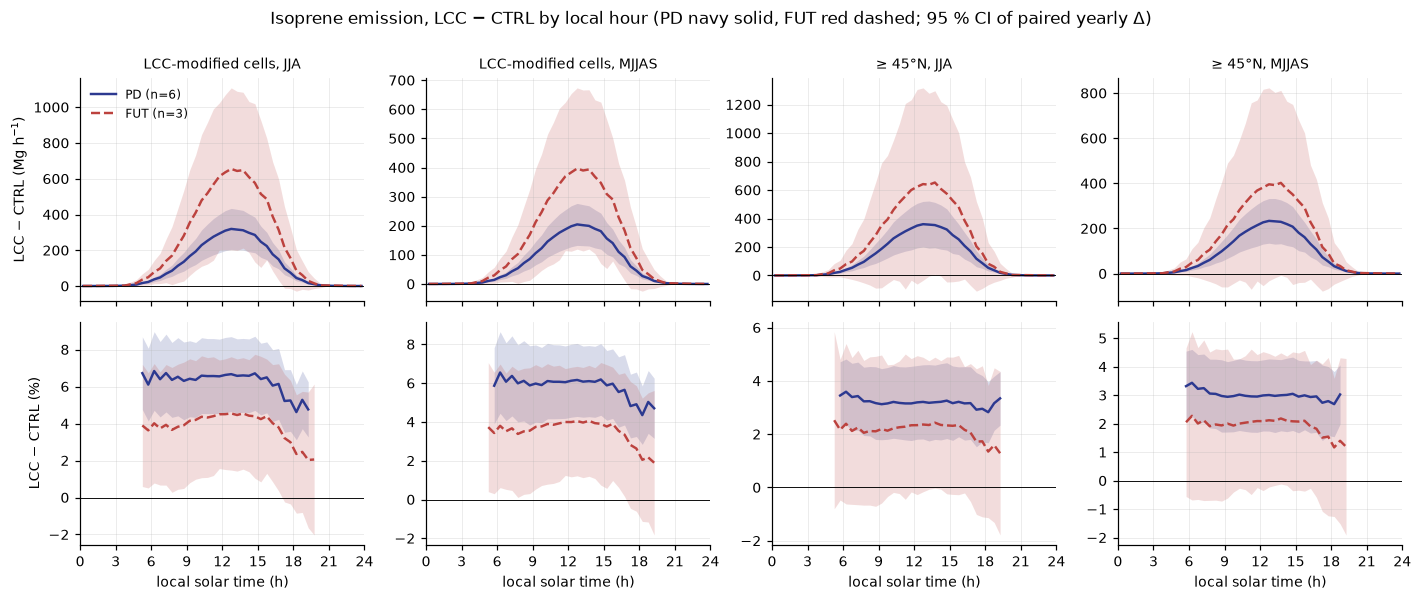

In [6]:
PERIODS_GS = {"JJA": [6, 7, 8], "MJJAS": [5, 6, 7, 8, 9]}

def delta_ci(r, p, mo):
    c = season_mean(REG[(r, "CTRL", p)], mo)
    l = season_mean(REG[(r, "LCC", p)], mo)
    d = l - c
    n = d.sizes["year"]
    m, se = d.mean("year"), d.std("year", ddof=1) / np.sqrt(n)
    h = se * stats.t.ppf(0.975, n - 1) if n > 1 else se * np.nan
    rel = 100 * d / c
    rel = rel.where(c.mean("year") > 0.05 * c.mean("year").max())
    rm = rel.mean("year")
    rh = rel.std("year", ddof=1) / np.sqrt(n) * stats.t.ppf(0.975, n - 1) if n > 1 else rm * np.nan
    return m, h, rm, rh, n

fig, axes = plt.subplots(2, len(REGIONS) * len(PERIODS_GS), figsize=(13, 5.4), sharex=True)
for i, r in enumerate(REGIONS):
    for k, (s, mo) in enumerate(PERIODS_GS.items()):
        col = i * len(PERIODS_GS) + k
        for p in ("PD", "FUT"):
            if not YEARS[p]:
                continue
            m, h, rm, rh, n = delta_ci(r, p, mo)
            c = GOLD if False else (NAVY if p == "PD" else RED)
            for row, (a, b) in enumerate([(m, h), (rm, rh)]):
                ax = axes[row, col]
                ax.plot(HOURS, a, color=c, ls=LS[p], lw=1.6, label=f"{p} (n={n})")
                ax.fill_between(HOURS, a - b, a + b, color=c, alpha=0.18, lw=0)
        for row in range(2):
            ax = axes[row, col]
            ax.axhline(0, color="k", lw=0.6)
            ax.grid(alpha=0.3, lw=0.5); ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
        axes[0, col].set_title(f"{r}, {s}", fontsize=9)
        axes[1, col].set_xlabel("local solar time (h)")
axes[0, 0].set_ylabel("LCC − CTRL (Mg h$^{-1}$)")
axes[1, 0].set_ylabel("LCC − CTRL (%)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Isoprene emission, LCC − CTRL by local hour (PD navy solid, FUT red dashed; 95 % CI of paired yearly Δ)", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_diurnal_lcc_minus_ctrl.png", dpi=200, bbox_inches="tight")

## 5. Month × local hour (LCC-modified cells)

CTRL emission rate and LCC − CTRL, mean over years, one panel per period.

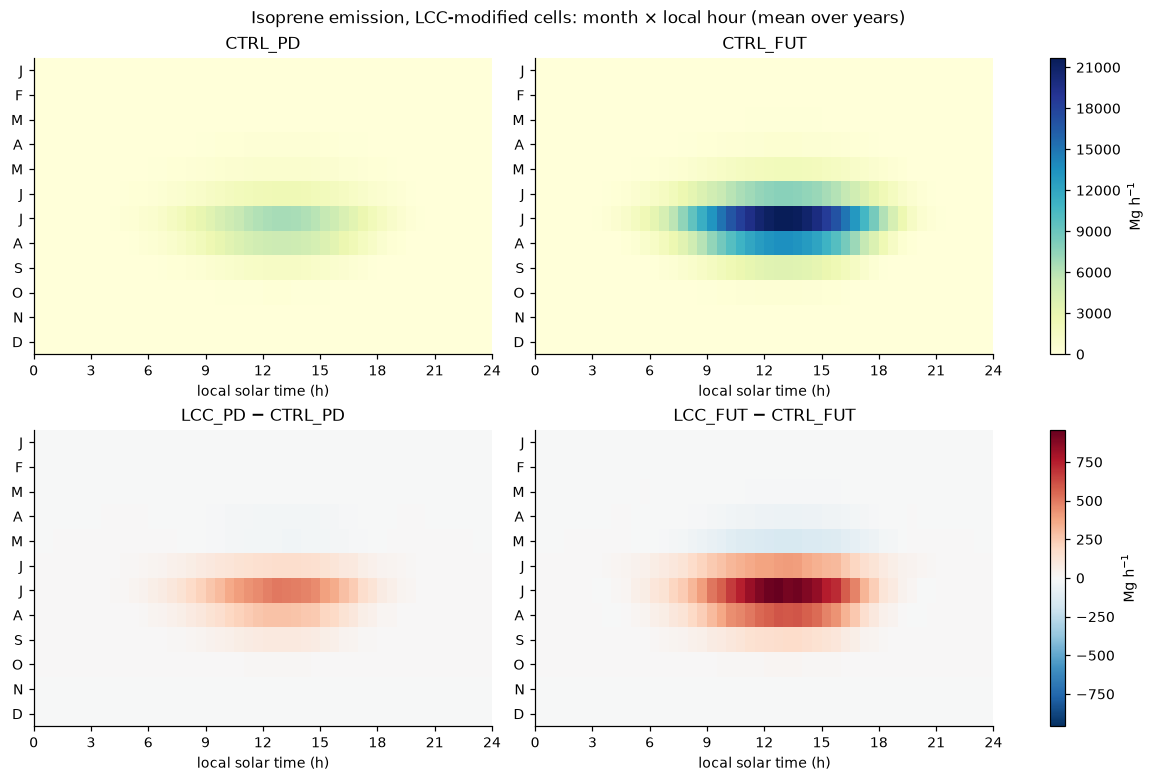

In [7]:
r = "LCC-modified cells"
pers = [p for p in ("PD", "FUT") if YEARS[p]]
from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(2, len(pers), figsize=(5.2 * len(pers), 7.0), squeeze=False, layout="constrained")
months = np.arange(1, 13)
vmax_abs = max(float(REG[(r, "CTRL", p)].mean("year").max()) for p in pers)
dmax = max(float(abs(REG[(r, "LCC", p)] - REG[(r, "CTRL", p)]).mean("year").max()) for p in pers)
for j, p in enumerate(pers):
    c = REG[(r, "CTRL", p)].mean("year")
    d = (REG[(r, "LCC", p)] - REG[(r, "CTRL", p)]).mean("year")
    im0 = axes[0, j].pcolormesh(np.arange(49) * 0.5, np.arange(0.5, 13.5), c.transpose("month", "lst"),
                                cmap="YlGnBu", vmin=0, vmax=vmax_abs, shading="flat")
    im1 = axes[1, j].pcolormesh(np.arange(49) * 0.5, np.arange(0.5, 13.5), d.transpose("month", "lst"),
                                cmap="RdBu_r", vmin=-dmax, vmax=dmax, shading="flat")
    axes[0, j].set_title(f"CTRL_{p}"); axes[1, j].set_title(f"LCC_{p} − CTRL_{p}")
    for ax in axes[:, j]:
        ax.set_yticks(months); ax.set_yticklabels("JFMAMJJASOND"); ax.invert_yaxis()
        ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("local solar time (h)")
fig.colorbar(im0, ax=axes[0, :], label="Mg h$^{-1}$", ticks=MaxNLocator(8))
fig.colorbar(im1, ax=axes[1, :], label="Mg h$^{-1}$", ticks=MaxNLocator(9, symmetric=True))
fig.suptitle(f"Isoprene emission, {r}: month × local hour (mean over years)")
fig.savefig(OUT / "figures/isoprene_month_by_hour_modified_cells.png", dpi=200, bbox_inches="tight")

## 6. Shape of the cycle by latitude (CTRL_PD, JJA)

Each band's JJA cycle normalised by its own daily mean (1 = flat). High latitudes in JJA have long days (polar day north of ~66°N), so the cycle should flatten northward. North of 75°N there is almost no isoprene, so the last band is 65–90°N. Tropics shown for reference.

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax wi

,band,peak_lst_h,peak_over_mean,min_over_mean
0,15°S–15°N,13.25,3.77,0.0
1,45–55°N,13.25,3.19,0.0
2,55–65°N,13.25,2.97,0.0
3,65–90°N,13.25,2.69,0.0


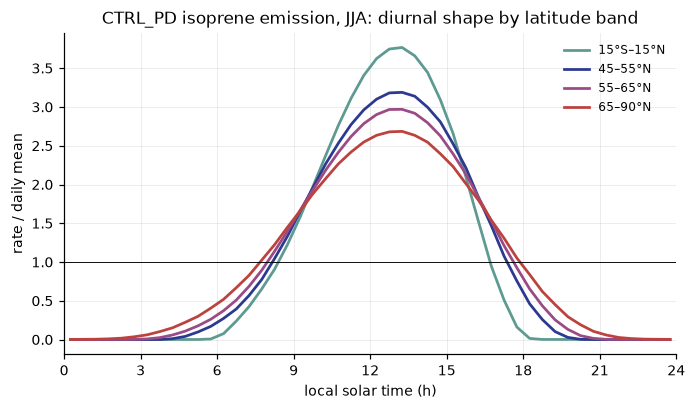

In [8]:
BANDS = {"15°S–15°N": (-15, 15), "45–55°N": (45, 55), "55–65°N": (55, 65), "65–90°N": (65, 90)}
BAND_COL = [TEAL, NAVY, PLUM, RED]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
shape_rows = []
for (b, (lo, hi)), c in zip(BANDS.items(), BAND_COL):
    m = xr.DataArray(np.broadcast_to((lat[:, None] >= lo) & (lat[:, None] < hi), area.shape), coords=area.coords)
    x = season_mean(regional_total(LST[("CTRL", "PD")], m), SEASONS["JJA"]).mean("year")
    norm = x / x.mean()
    ax.plot(HOURS, norm, color=c, lw=1.8, label=b)
    shape_rows.append(dict(band=b, peak_lst_h=float(HOURS[int(x.argmax())]), peak_over_mean=float(norm.max()),
                           min_over_mean=float(norm.min())))
ax.axhline(1, color="k", lw=0.6)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.grid(alpha=0.3, lw=0.5)
ax.set_xlabel("local solar time (h)"); ax.set_ylabel("rate / daily mean")
ax.legend(frameon=False, fontsize=8)
ax.set_title("CTRL_PD isoprene emission, JJA: diurnal shape by latitude band")
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_diurnal_shape_by_latitude_JJA.png", dpi=200, bbox_inches="tight")
pd.DataFrame(shape_rows).round(2)

## 7. Summary table

Per region, run and season (mean over years): peak local hour, peak / daily-mean ratio, and the **night share** = fraction of the daily emission between 18 and 06 local solar time.

In [9]:
rows = []
night = (HOURS < 6) | (HOURS >= 18)
for (r, v, p), x in REG.items():
    for s, mo in SEASONS.items():
        xm = season_mean(x, mo).mean("year")
        if float(xm.sum()) == 0:
            continue
        rows.append(dict(region=r, alias=f"{v}_{p}", season=s,
                         mean_Mg_per_h=float(xm.mean()), peak_lst_h=float(HOURS[int(xm.argmax())]),
                         peak_over_mean=float(xm.max() / xm.mean()), night_share_pct=float(100 * xm[night].sum() / xm.sum())))
summary = pd.DataFrame(rows).round(3)
summary.to_csv(OUT / "tables/isoprene_diurnal_summary.csv", index=False)
summary[summary.season.isin(["JJA", "MAM", "SON"])]

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax wi

,region,alias,season,mean_Mg_per_h,peak_lst_h,peak_over_mean,night_share_pct
1,LCC-modified cells,CTRL_PD,MAM,127.701,12.75,3.164,3.254
2,LCC-modified cells,CTRL_PD,JJA,1570.718,13.25,3.023,4.218
3,LCC-modified cells,CTRL_PD,SON,144.986,12.75,3.656,0.525
5,LCC-modified cells,LCC_PD,MAM,122.131,12.75,3.133,3.478
6,LCC-modified cells,LCC_PD,JJA,1672.575,13.25,3.027,4.180
7,LCC-modified cells,LCC_PD,SON,153.917,12.75,3.663,0.520
9,LCC-modified cells,CTRL_FUT,MAM,298.166,13.25,3.048,3.899
10,LCC-modified cells,CTRL_FUT,JJA,5065.013,13.25,2.845,5.122
11,LCC-modified cells,CTRL_FUT,SON,391.190,13.25,3.552,0.582
13,LCC-modified cells,LCC_FUT,MAM,276.095,13.25,3.024,4.112
